# 02 – Training B0, B1 and B2

| Model | What it adds | Training images |
|---|---|---|
| **B0** | ResNet-50 with an object head (16 sigmoid outputs) | multi-label train images |
| **B1** | B0 + a scene head trained with the scene labels (multi-task) | multi-label train images + scene-only images |
| **B2** | B1 + the scene prior P(object \| scene) added to the object logits | same as B1 |

Every run is saved to `results/` (metrics, training history, test predictions) and `checkpoints/` (weights).
A run whose result file already exists is skipped, so the notebook can be stopped and restarted.
`run_all` and `plot_history` are defined in `aidml.py` because `03_control_experiments.ipynb` uses them too.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from aidml import (IMAGENET_MEAN, IMAGENET_STD, get_device, load_data, load_runs, make_batch, plot_history,
                   run_all, split_indices)

device = get_device()
data = load_data()
print("device:", device)
for name in ["train", "val", "test", "extra"]:
    print(f"{name:6s}", len(split_indices(data, name)))

device: mps
train  2160
val    240
test   600
extra  7000


## 2. Configuration

- `lr` / `head_lr`: AdamW learning rates for the pretrained backbone and for the new layers (heads and prior weights).
  The learning rate follows a cosine schedule.
- `extra_ratio`: for B1 and B2, every epoch uses all multi-label training images plus this many times as many
  randomly drawn scene-only images. With 1.0, each batch is about half multi-label and half scene-only images,
  and B1/B2 see the multi-label images exactly as often as B0.
- `scene_loss_weight`: weight of the scene cross-entropy relative to the object BCE.
- The epoch with the best validation mAP is kept.

Three seeds are planned. After the first B1 run, check the printed time per epoch: if three seeds of every model
do not fit into the available time, set `SEEDS = [0]`.

In [2]:
CONFIG = {
    "epochs": 20,
    "batch_size": 32,
    "lr": 1e-4,
    "head_lr": 1e-3,
    "weight_decay": 1e-4,
    "extra_ratio": 1.0,
    "scene_loss_weight": 1.0,
    "pretrained": True,
}
SEEDS = [0, 1, 2]

## 3. Check the input pipeline

Random training images after augmentation (random 90° rotation and horizontal flip), converted back to RGB for display.

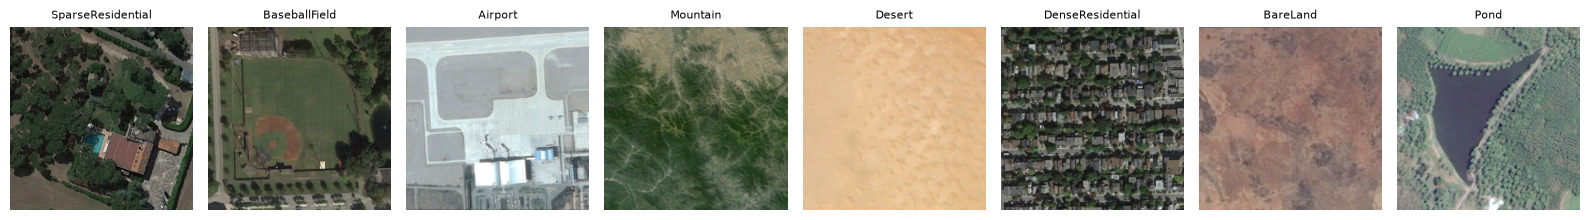

In [3]:
idx = np.random.default_rng(0).choice(split_indices(data, "train"), 8, replace=False)
batch = make_batch(data["images"], idx, torch.device("cpu"), augment=True)
batch = (batch * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, image, i in zip(axes, batch, idx):
    ax.imshow(image)
    ax.set_title(data["scene_names"][data["scenes"][i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. B0 – baseline

In [5]:
run_all("B0", SEEDS, data, CONFIG, device)

--- B0_seed0 ---


/Users/yagizcetin/Documents/Github/CS415-CourseProject/aidml.py:198: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:212.)
  scenes = torch.from_numpy(data["scenes"])


epoch  1 | object loss 0.3064 | scene loss 0.0000 | val mAP 0.7482 | 72 s
epoch  2 | object loss 0.1763 | scene loss 0.0000 | val mAP 0.8445 | 64 s
epoch  3 | object loss 0.1347 | scene loss 0.0000 | val mAP 0.8639 | 65 s
epoch  4 | object loss 0.1127 | scene loss 0.0000 | val mAP 0.8651 | 84 s
epoch  5 | object loss 0.0986 | scene loss 0.0000 | val mAP 0.8816 | 87 s
epoch  6 | object loss 0.0811 | scene loss 0.0000 | val mAP 0.8824 | 79 s
epoch  7 | object loss 0.0692 | scene loss 0.0000 | val mAP 0.8794 | 81 s
epoch  8 | object loss 0.0575 | scene loss 0.0000 | val mAP 0.8786 | 82 s
epoch  9 | object loss 0.0469 | scene loss 0.0000 | val mAP 0.8686 | 84 s
epoch 10 | object loss 0.0398 | scene loss 0.0000 | val mAP 0.8808 | 88 s
epoch 11 | object loss 0.0349 | scene loss 0.0000 | val mAP 0.8700 | 83 s
epoch 12 | object loss 0.0299 | scene loss 0.0000 | val mAP 0.8858 | 79 s
epoch 13 | object loss 0.0245 | scene loss 0.0000 | val mAP 0.8818 | 79 s
epoch 14 | object loss 0.0227 | scene 

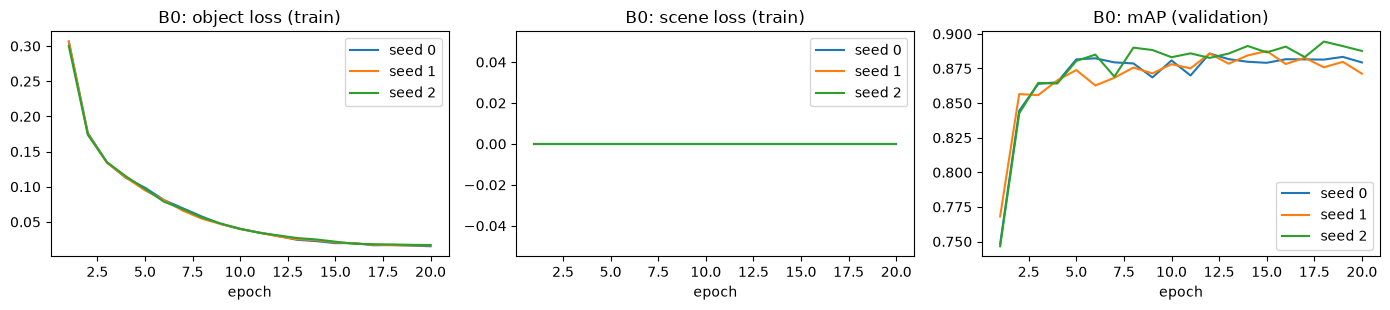

In [6]:
plot_history("B0")

## 5. B1 – multi-task with the scene head

In [7]:
run_all("B1", SEEDS, data, CONFIG, device)

--- B1_seed0 ---
epoch  1 | object loss 0.2518 | scene loss 1.0484 | val mAP 0.8434 | 166 s
epoch  2 | object loss 0.1515 | scene loss 0.2167 | val mAP 0.8617 | 187 s
epoch  3 | object loss 0.1400 | scene loss 0.1726 | val mAP 0.8649 | 182 s
epoch  4 | object loss 0.1234 | scene loss 0.1114 | val mAP 0.8701 | 178 s
epoch  5 | object loss 0.1162 | scene loss 0.1023 | val mAP 0.8725 | 177 s
epoch  6 | object loss 0.1068 | scene loss 0.0777 | val mAP 0.8750 | 147 s
epoch  7 | object loss 0.0976 | scene loss 0.0686 | val mAP 0.8801 | 184 s
epoch  8 | object loss 0.0936 | scene loss 0.0496 | val mAP 0.8724 | 174 s
epoch  9 | object loss 0.0843 | scene loss 0.0447 | val mAP 0.8762 | 163 s
epoch 10 | object loss 0.0786 | scene loss 0.0304 | val mAP 0.8747 | 156 s
epoch 11 | object loss 0.0711 | scene loss 0.0246 | val mAP 0.8775 | 153 s
epoch 12 | object loss 0.0649 | scene loss 0.0278 | val mAP 0.8799 | 161 s
epoch 13 | object loss 0.0627 | scene loss 0.0289 | val mAP 0.8896 | 168 s
epoch 14

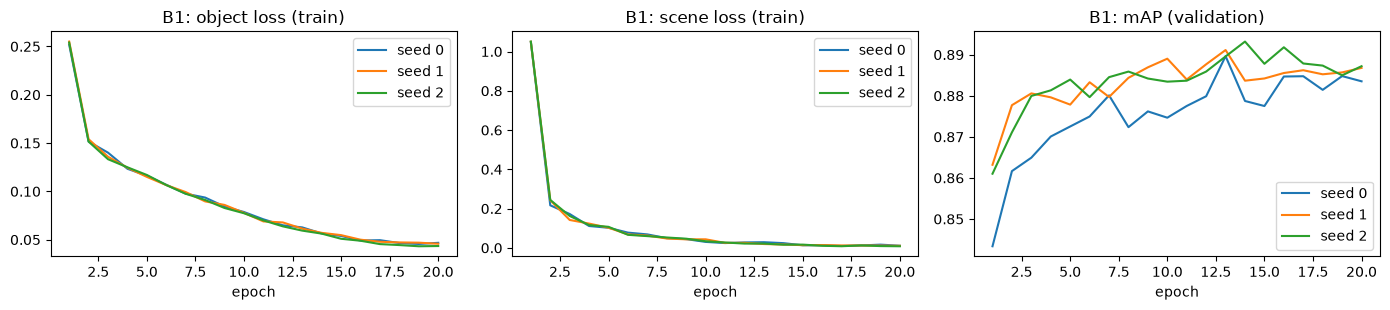

In [8]:
plot_history("B1")

## 6. B2 – multi-task with the scene prior

In [9]:
run_all("B2", SEEDS, data, CONFIG, device)

--- B2_seed0 ---
epoch  1 | object loss 0.2490 | scene loss 1.0478 | val mAP 0.8577 | 138 s
epoch  2 | object loss 0.1495 | scene loss 0.2246 | val mAP 0.8659 | 145 s
epoch  3 | object loss 0.1375 | scene loss 0.1652 | val mAP 0.8766 | 140 s
epoch  4 | object loss 0.1220 | scene loss 0.1120 | val mAP 0.8858 | 134 s
epoch  5 | object loss 0.1140 | scene loss 0.1043 | val mAP 0.8849 | 133 s
epoch  6 | object loss 0.1053 | scene loss 0.0843 | val mAP 0.8840 | 133 s
epoch  7 | object loss 0.0970 | scene loss 0.0666 | val mAP 0.8906 | 141 s
epoch  8 | object loss 0.0917 | scene loss 0.0499 | val mAP 0.8906 | 149 s
epoch  9 | object loss 0.0814 | scene loss 0.0403 | val mAP 0.8898 | 151 s
epoch 10 | object loss 0.0758 | scene loss 0.0352 | val mAP 0.8904 | 143 s
epoch 11 | object loss 0.0705 | scene loss 0.0325 | val mAP 0.8906 | 143 s
epoch 12 | object loss 0.0651 | scene loss 0.0327 | val mAP 0.8959 | 155 s
epoch 13 | object loss 0.0623 | scene loss 0.0275 | val mAP 0.8953 | 144 s
epoch 14

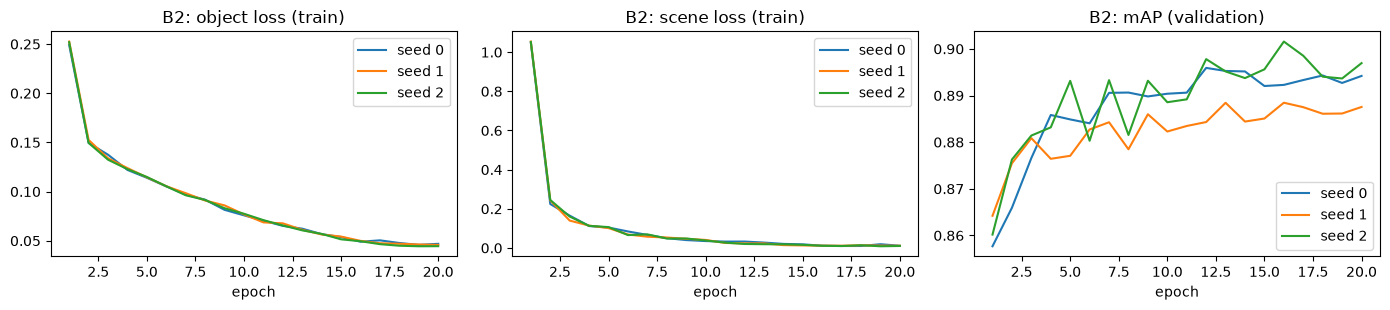

In [10]:
plot_history("B2")

## 7. Quick summary

Test metrics, mean ± standard deviation over the finished seeds. Tables and figures for the report are made in
`05_results.ipynb`.

In [11]:
rows = []
for model_name in ["B0", "B1", "B2"]:
    for run in load_runs(model_name):
        metrics = {k: v for k, v in run["test_metrics"].items() if not isinstance(v, list)}
        rows.append({"model": model_name, "seed": run["seed"], **metrics})
summary = pd.DataFrame(rows).drop(columns="seed").groupby("model").agg(["mean", "std"])
summary.round(4)

mAP         example_F1         example_F2         example_precision  \
         mean     std       mean     std       mean     std              mean   
model                                                                           
B0     0.8968  0.0055     0.9102  0.0045     0.9100  0.0050            0.9272   
B1     0.9063  0.0005     0.9143  0.0044     0.9156  0.0057            0.9279   
B2     0.9089  0.0040     0.9163  0.0019     0.9180  0.0025            0.9290   

              example_recall         macro_F1         scene_accuracy          
          std           mean     std     mean     std           mean     std  
model                                                                         
B0     0.0036         0.9140  0.0054   0.8419  0.0086            NaN     NaN  
B1     0.0013         0.9206  0.0067   0.8489  0.0041         0.9717  0.0044  
B2     0.0049         0.9234  0.0036   0.8561  0.0052         0.9744  0.0019